# MIT ACADEMY OF ENGINEERING, ALANDI (D), PUNE
### DEPARTMENT OF COMPUTER ENGINEERING | ACADEMIC YEAR: 2026–2027
### THIRD YEAR B.TECH (SEMESTER - V)
### COURSE: ARTIFICIAL INTELLIGENCE AND MACHINE LEARNING (COURSE CODE: 2304322T)
### ACTIVITY NO. 2: Implementation and Performance Evaluation with Comparative Analysis of Machine Learning Models for Selected Real-Time Applications

---
- **Student Name:** Tejas / Candidate
- **Seat Number:** TY-BTECH-V-01
- **PRN Number:** 202401040128
- **Selected Real-Time Application:** Clinical Decision Support System (CDSS) for Cardiovascular Disease (Coronary Artery Disease) Risk Stratification
- **Benchmark Algorithms Evaluated:** 8 Models (Logistic Regression, Gaussian Naive Bayes, KNN, Decision Tree, SVM, MLP Neural Network, Random Forest, Gradient Boosting)
- **Course Outcomes:** CO1 | **Program Outcomes:** PO1, PO2, PO3, PO5, PO8, PO10, PO12 | **RBT Level:** Level 4
---


## Step 1: Problem Statement & Real-Time Application Domain (CO1, PO1, PO2)
### Domain: Healthcare Informatics & Clinical Decision Support Systems (CDSS)
### Problem Statement:
Implementation and Performance Evaluation with Comparative Analysis of Machine Learning Models for Non-Invasive Early Detection and Risk Stratification of Coronary Artery Disease (CAD).

### Clinical Significance & Societal Relevance:
Cardiovascular diseases (CVDs) remain the leading etiology of mortality worldwide, claiming an estimated 17.9 million lives each year according to the World Health Organization (WHO). Invasive coronary angiography remains the gold standard but is cost-prohibitive, invasive, and carries procedural risks. Machine learning models offer non-invasive, objective, and high-precision risk stratification from routine non-invasive clinical tests (age, resting blood pressure, serum cholesterol, resting ECG, peak heart rate, ST-depression, and exercise-induced angina).


## Step 2: Machine Learning Software Development Workflow (Phases 1-7)
### Phase 1: Data Collection & Attribute Dictionary
Dataset: Cleveland Clinic Foundation Heart Disease Benchmark (UCI Machine Learning Repository).


In [1]:
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Suppress loky CPU count warning on modern Windows 11 builds
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 4))

# Compatibility shim: Scikit-learn Cython extension module alias
if "_loss" not in sys.modules:
    try:
        import sklearn._loss._loss as _loss_cython
        sys.modules["_loss"] = _loss_cython
    except (ImportError, ModuleNotFoundError):
        pass

from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve, auc
)

# Core ML Algorithms spanning all major paradigms
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 150

# Load dataset
data_path = "heart_disease_uci.csv" if os.path.exists("heart_disease_uci.csv") else "AIML_Mini_Project-main/heart_disease_uci.csv"
df = pd.read_csv(data_path)

print(f"Dataset Loaded Successfully: {df.shape[0]} patient instances, {df.shape[1]} clinical attributes")
print(df.head())


Dataset Loaded Successfully: 303 patient instances, 14 clinical attributes
    age  sex   cp  trestbps   chol  ...  oldpeak  slope   ca  thal  target
0  63.0  1.0  1.0     145.0  233.0  ...      2.3    3.0  0.0   6.0       0
1  67.0  1.0  4.0     160.0  286.0  ...      1.5    2.0  3.0   3.0       1
2  67.0  1.0  4.0     120.0  229.0  ...      2.6    2.0  2.0   7.0       1
3  37.0  1.0  3.0     130.0  250.0  ...      3.5    3.0  0.0   3.0       0
4  41.0  0.0  2.0     130.0  204.0  ...      1.4    1.0  0.0   3.0       0

[5 rows x 14 columns]


### Clinical Attribute Dictionary
| Attribute | Description & Unit | Variable Type | Biological / Clinical Significance |
|:---|:---|:---|:---|
| **age** | Patient Age (Years) | Continuous | Arterial stiffness and atherosclerotic burden escalate with age |
| **sex** | Biological Sex (1=Male, 0=Female) | Binary | Higher pre-menopausal protective estrogen in females; earlier male onset |
| **cp** | Chest Pain Type (1: Typical, 2: Atypical, 3: Non-Anginal, 4: Asymptomatic) | Nominal | Type 4 (asymptomatic) frequently signals dangerous silent ischemia |
| **trestbps** | Resting Blood Pressure (mmHg) | Continuous | Chronic shear stress injures vascular endothelium ($>140$ mmHg = hypertension) |
| **chol** | Serum Cholesterol (mg/dL) | Continuous | High LDL accelerates coronary atheromatous plaque formation |
| **fbs** | Fasting Blood Sugar $>120$ mg/dL | Binary | Diabetes is a primary coronary risk accelerator |
| **restecg** | Resting Electrocardiographic Results | Nominal | 0: Normal, 1: ST-T wave abnormality, 2: Left ventricular hypertrophy |
| **thalach** | Maximum Heart Rate Achieved (bpm) | Continuous | Impairment signifies chronotropic incompetence |
| **exang** | Exercise-Induced Angina (1=Yes, 0=No) | Binary | Indicates myocardial oxygen supply-demand mismatch under exertion |
| **oldpeak** | ST Depression Induced by Exercise (mm) | Continuous | Electrocardiographic hallmark of subendocardial ischemia |
| **slope** | Slope of Peak Exercise ST Segment | Ordinal | 1: Upsloping, 2: Flat, 3: Downsloping (downsloping = severe CAD) |
| **ca** | Major Vessels (0-3) Colored by Fluoroscopy | Discrete / Ordinal | Direct anatomical marker of significant coronary vessel stenosis |
| **thal** | Thallium Scintigraphy Defect Status | Nominal | 3: Normal, 6: Fixed defect (prior infarction), 7: Reversible defect (ischemia) |
| **target** | Diagnostic Status (0=Healthy, 1=CAD) | Binary Target | Ground-truth CAD presence validated by cardiac catheterization |


### Phase 2: Statistical Summary & Descriptive Statistics


In [2]:
continuous_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
stat_summary = pd.DataFrame(index=continuous_cols)

stat_summary["Mean"] = df[continuous_cols].mean()
stat_summary["Median"] = df[continuous_cols].median()
stat_summary["Std Dev"] = df[continuous_cols].std()
stat_summary["Variance"] = df[continuous_cols].var()
stat_summary["Min"] = df[continuous_cols].min()
stat_summary["Max"] = df[continuous_cols].max()
stat_summary["IQR"] = df[continuous_cols].quantile(0.75) - df[continuous_cols].quantile(0.25)
stat_summary["Skewness"] = df[continuous_cols].skew()
stat_summary["Kurtosis"] = df[continuous_cols].kurtosis()

print("Comprehensive Descriptive Statistics of Continuous Predictors:")
print(stat_summary.round(3))


Comprehensive Descriptive Statistics of Continuous Predictors:
             Mean  Median  Std Dev  ...   IQR  Skewness  Kurtosis
age        54.439    56.0    9.039  ...  13.0    -0.209    -0.523
trestbps  131.690   130.0   17.600  ...  20.0     0.706     0.880
chol      246.693   241.0   51.777  ...  64.0     1.136     4.492
thalach   149.607   153.0   22.875  ...  32.5    -0.537    -0.054
oldpeak     1.040     0.8    1.161  ...   1.6     1.270     1.576

[5 rows x 9 columns]


### Phase 3: Exploratory Data Analysis & Visualizations


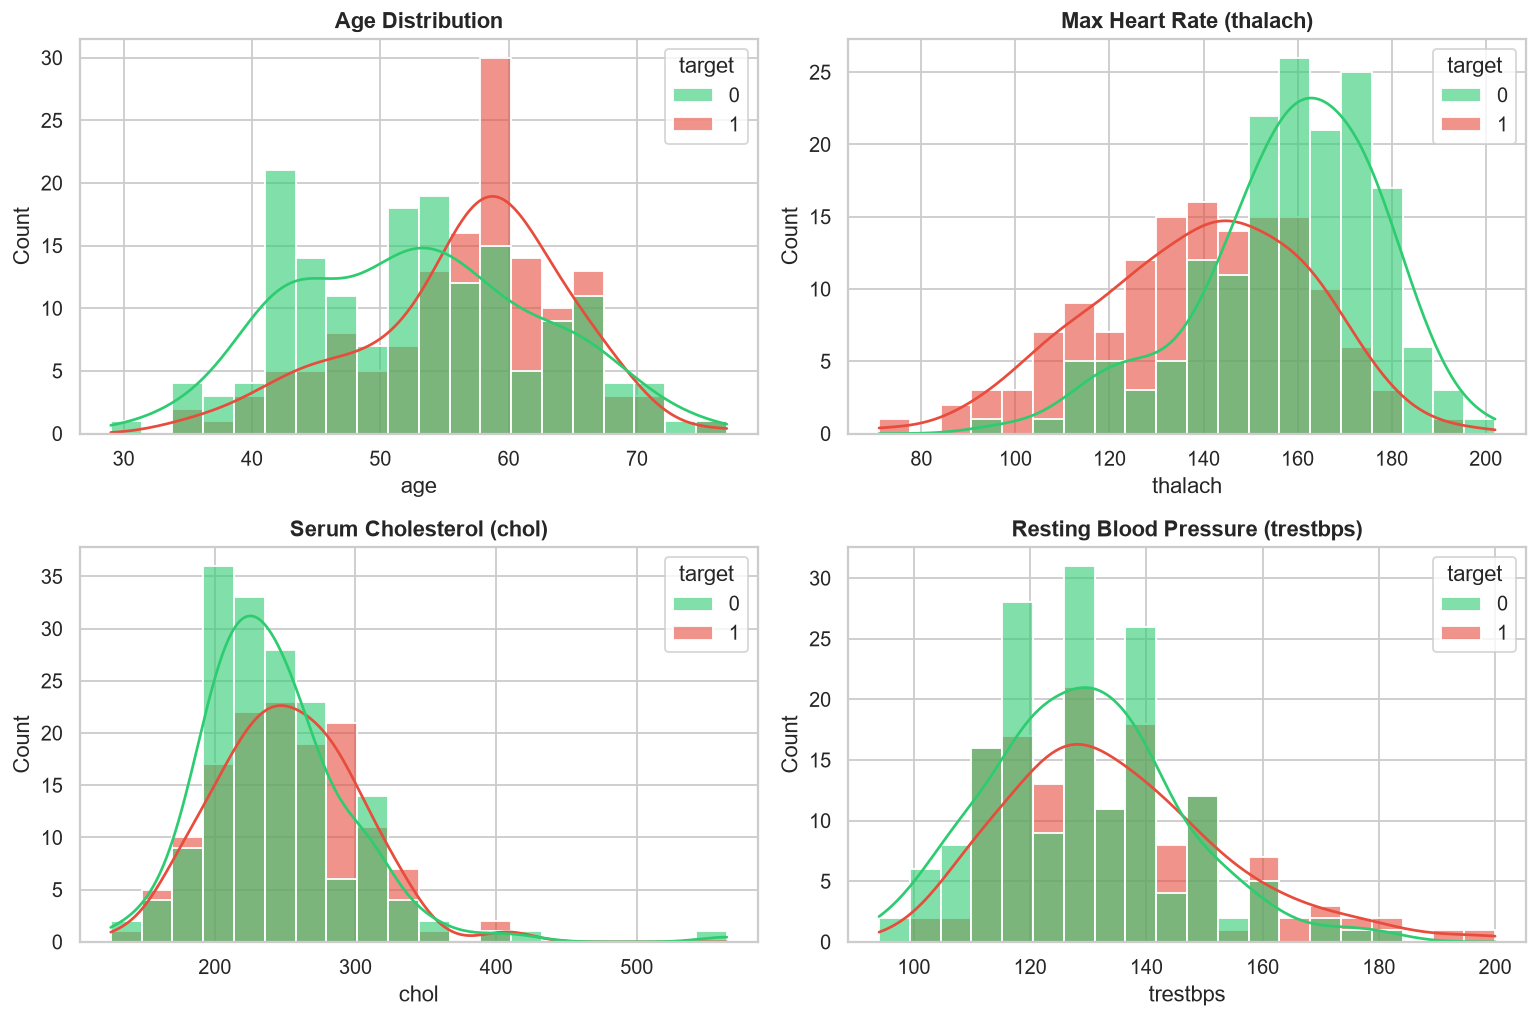

In [3]:
# 1. Feature Distributions Grouped by Target Class
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
features_to_plot = ["age", "thalach", "chol", "trestbps"]
titles = ["Age Distribution", "Max Heart Rate (thalach)", "Serum Cholesterol (chol)", "Resting Blood Pressure (trestbps)"]

for ax, feat, title in zip(axes.flat, features_to_plot, titles):
    sns.histplot(data=df, x=feat, hue="target", kde=True, ax=ax, palette=["#2ecc71", "#e74c3c"], bins=20, alpha=0.6)
    ax.set_title(title, weight='bold')
plt.tight_layout()
plt.show()


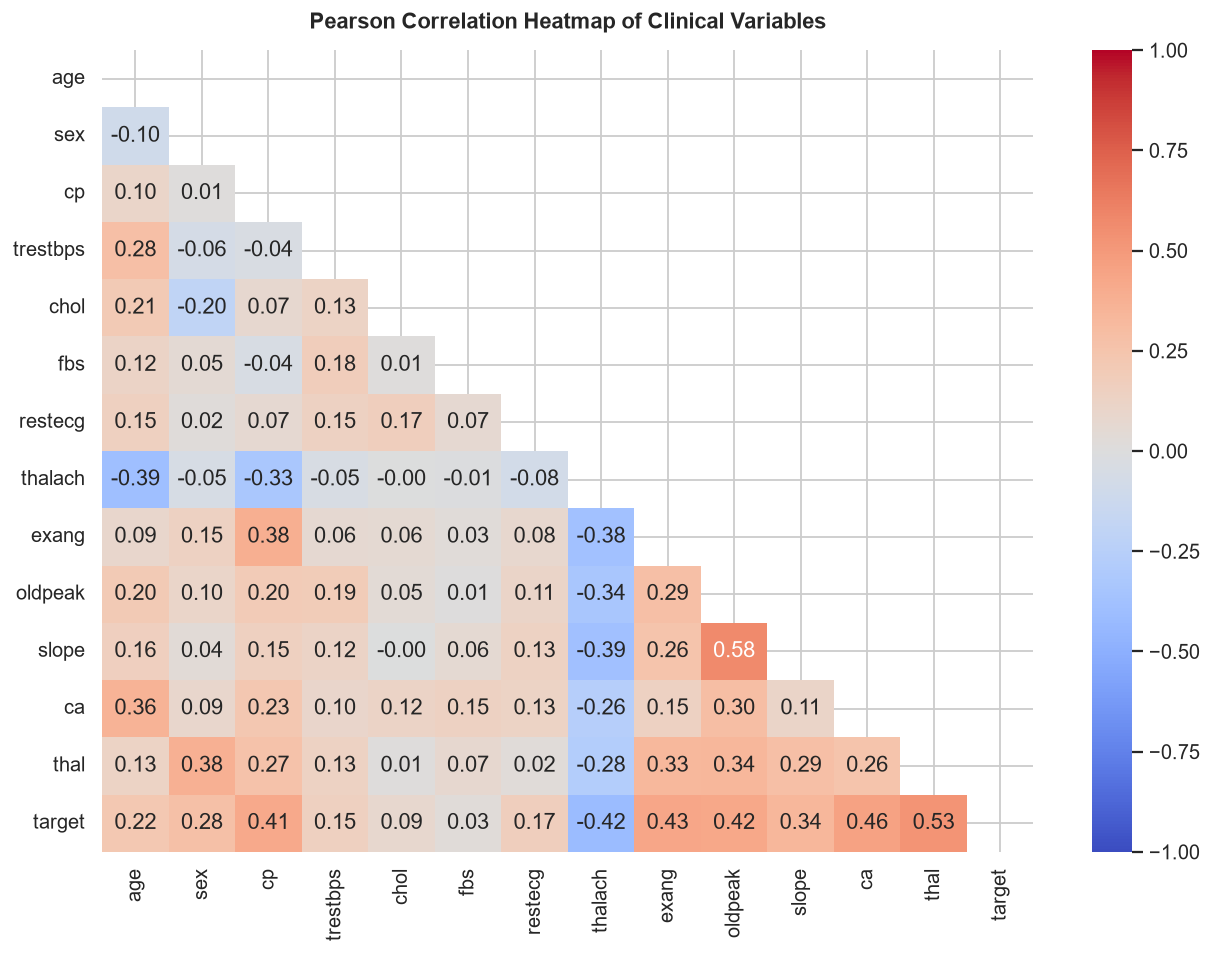

In [4]:
# 2. Pearson Correlation Heatmap
plt.figure(figsize=(10, 7.5))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson Correlation Heatmap of Clinical Variables", weight='bold', pad=12)
plt.tight_layout()
plt.show()


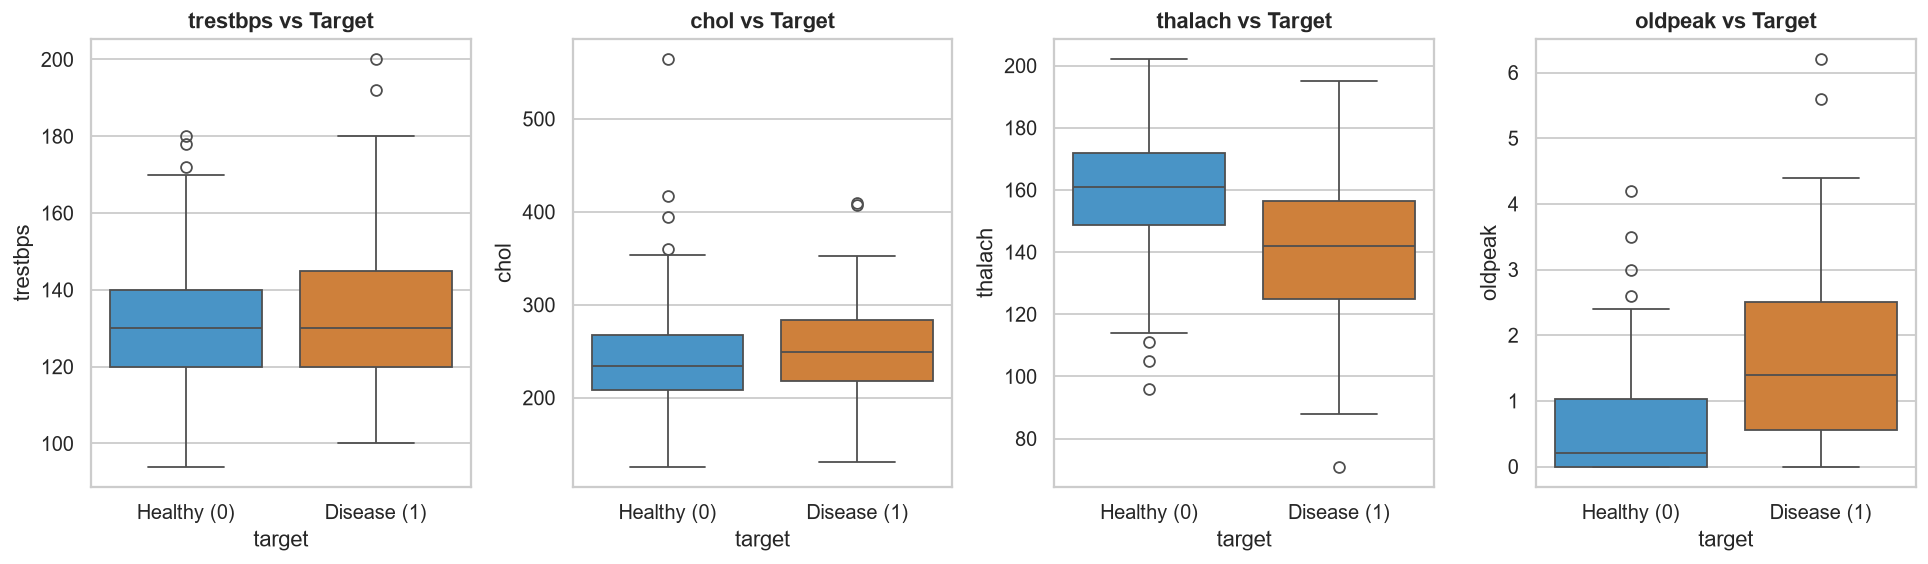

In [5]:
# 3. Outlier Identification via Boxplots
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for ax, feat in zip(axes, ["trestbps", "chol", "thalach", "oldpeak"]):
    sns.boxplot(data=df, y=feat, x="target", hue="target", ax=ax, palette=["#3498db", "#e67e22"], legend=False)
    ax.set_title(f"{feat} vs Target", weight='bold')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Healthy (0)", "Disease (1)"])
plt.tight_layout()
plt.show()


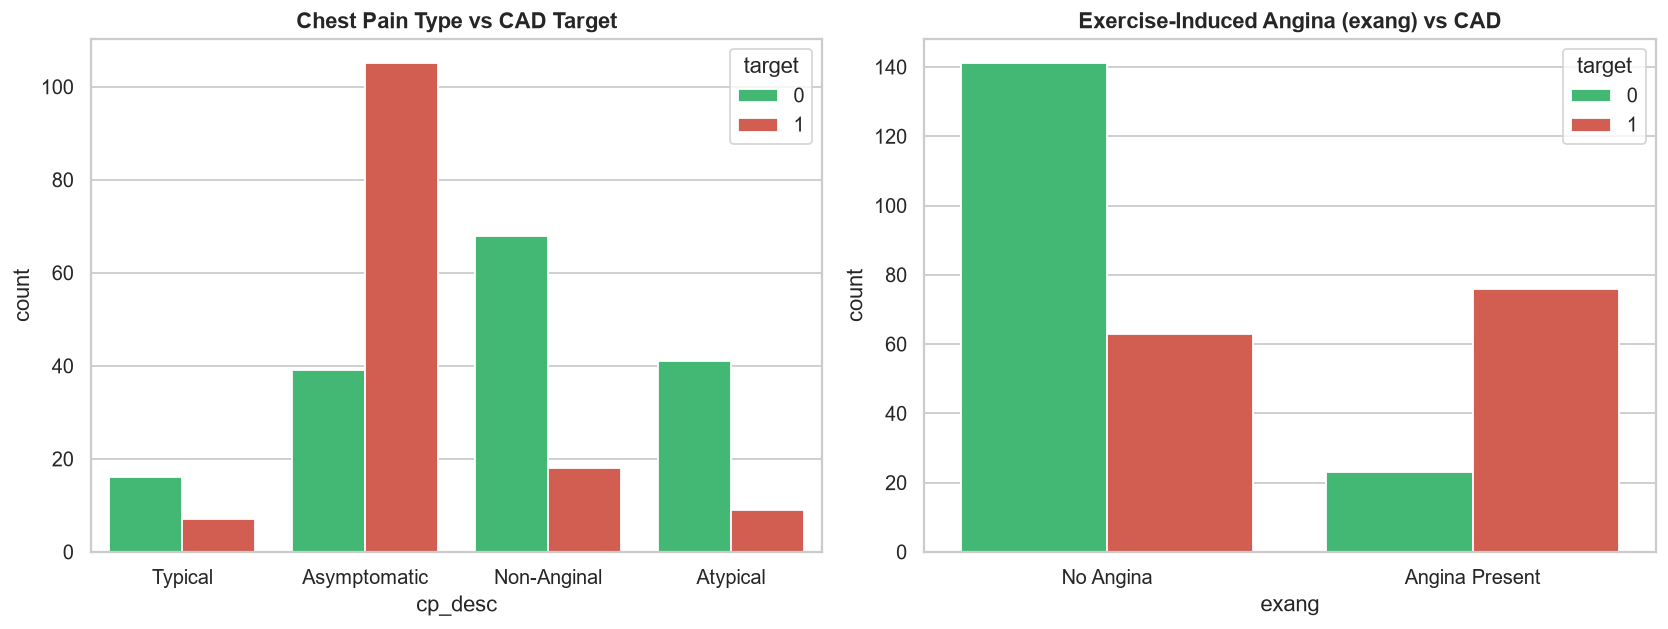

In [6]:
# 4. Categorical Clinical Risk Factors
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cp_map = {1: "Typical", 2: "Atypical", 3: "Non-Anginal", 4: "Asymptomatic"}
df_plot = df.copy()
df_plot['cp_desc'] = df_plot['cp'].map(cp_map)
sns.countplot(data=df_plot, x="cp_desc", hue="target", ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_title("Chest Pain Type vs CAD Target", weight='bold')

sns.countplot(data=df_plot, x="exang", hue="target", ax=axes[1], palette=["#2ecc71", "#e74c3c"])
axes[1].set_title("Exercise-Induced Angina (exang) vs CAD", weight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["No Angina", "Angina Present"])
plt.tight_layout()
plt.show()


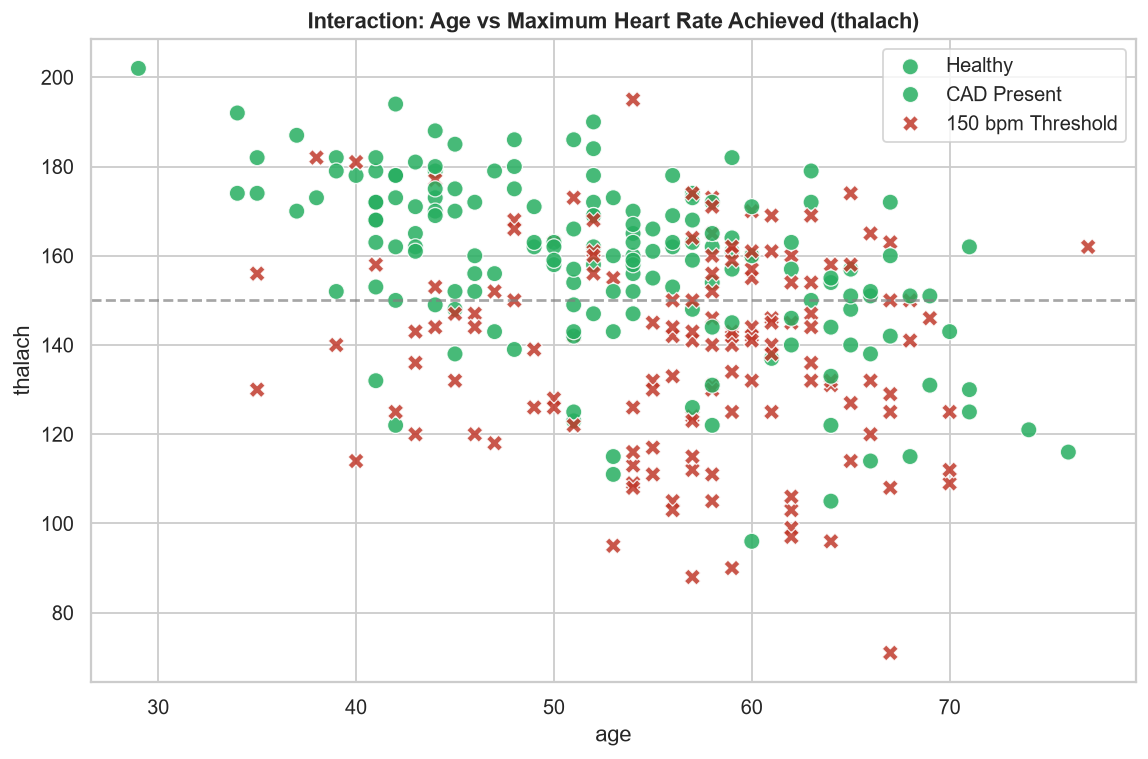

In [7]:
# 5. Bivariate Interaction: Age vs Peak Heart Rate
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="age", y="thalach", hue="target", style="target", s=80, alpha=0.85, palette=["#27ae60", "#c0392b"])
plt.axhline(150, color='grey', linestyle='--', alpha=0.7, label='Reference 150 bpm')
plt.title("Interaction: Age vs Maximum Heart Rate Achieved (thalach)", weight='bold')
plt.legend(["Healthy", "CAD Present", "150 bpm Threshold"])
plt.tight_layout()
plt.show()


### Phase 4 & 5: Stratified Train-Test Splitting & Zero-Leakage Preprocessing
To strictly eliminate data leakage:
1. The dataset is partitioned into 80% training and 20% testing partitions FIRST.
2. Missing value imputations and Winsorization thresholds are calculated solely from `X_train_raw`.
3. The `StandardScaler` is fitted solely on `X_train_enc` and transformed onto `X_test_enc`.


In [8]:
# Step 1: Partition raw data FIRST to completely prevent data leakage
X_raw = df.drop(columns=['target'])
y = df['target'].astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

# Step 2: Imputation parameters computed STRICTLY from X_train_raw
ca_impute_value = X_train_raw['ca'].median()
thal_impute_value = X_train_raw['thal'].mode()[0]

X_train_imp = X_train_raw.copy()
X_test_imp = X_test_raw.copy()

X_train_imp['ca'] = X_train_imp['ca'].fillna(ca_impute_value)
X_test_imp['ca'] = X_test_imp['ca'].fillna(ca_impute_value)

X_train_imp['thal'] = X_train_imp['thal'].fillna(thal_impute_value)
X_test_imp['thal'] = X_test_imp['thal'].fillna(thal_impute_value)

# Step 3: Outlier Winsorization thresholds computed STRICTLY from X_train_raw
chol_cap = X_train_imp['chol'].quantile(0.99)
trestbps_cap = X_train_imp['trestbps'].quantile(0.99)

X_train_imp['chol'] = np.where(X_train_imp['chol'] > chol_cap, chol_cap, X_train_imp['chol'])
X_test_imp['chol'] = np.where(X_test_imp['chol'] > chol_cap, chol_cap, X_test_imp['chol'])

X_train_imp['trestbps'] = np.where(X_train_imp['trestbps'] > trestbps_cap, trestbps_cap, X_train_imp['trestbps'])
X_test_imp['trestbps'] = np.where(X_test_imp['trestbps'] > trestbps_cap, trestbps_cap, X_test_imp['trestbps'])

# Step 4: Categorical One-Hot Encoding aligned across train and test
categorical_nominal = ['cp', 'restecg', 'slope', 'thal']
X_train_enc = pd.get_dummies(X_train_imp, columns=categorical_nominal, drop_first=True, dtype=int)
X_test_enc = pd.get_dummies(X_test_imp, columns=categorical_nominal, drop_first=True, dtype=int)

feature_cols = list(X_train_enc.columns)
X_test_enc = X_test_enc.reindex(columns=feature_cols, fill_value=0)

# Step 5: StandardScaler fitted STRICTLY on X_train_enc
scaler = StandardScaler()
continuous_in_encoded = [c for c in continuous_cols if c in X_train_enc.columns]

X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()

X_train_scaled[continuous_in_encoded] = scaler.fit_transform(X_train_enc[continuous_in_encoded])
X_test_scaled[continuous_in_encoded] = scaler.transform(X_test_enc[continuous_in_encoded])

print(f"Zero-Leakage Preprocessing Complete!")
print(f"Training Instances: {X_train_scaled.shape[0]} | Testing Instances: {X_test_scaled.shape[0]}")
print(f"Total Predictors: {len(feature_cols)}")


Zero-Leakage Preprocessing Complete!
Training Instances: 242 | Testing Instances: 61
Total Predictors: 18


### Phase 6: Hyperparameter Optimization via Stratified GridSearchCV
Optimization performed on Random Forest to identify optimal regularized ensemble depth, split criteria, and estimator count.


In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 8],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'criterion': ['gini', 'entropy']
}

print("Executing Stratified 5-Fold GridSearchCV on Random Forest...")
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=skf,
    scoring='roc_auc',
    n_jobs=1
)
grid_search.fit(X_train_scaled, y_train)

best_rf = grid_search.best_estimator_
print(f"Optimal Hyperparameters: {grid_search.best_params_}")
print(f"Best 5-Fold CV ROC-AUC: {grid_search.best_score_:.4f}")


Executing Stratified 5-Fold GridSearchCV on Random Forest...
Optimal Hyperparameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 150}
Best 5-Fold CV ROC-AUC: 0.8979


## Steps 3 & 4: Performance Evaluation & Comparative Analysis (8 Models)
Evaluation across all metrics: Accuracy, Precision, Recall/Sensitivity, Specificity, F1-Score, ROC-AUC, 5-Fold Cross-Validation, Training Time, and Inference Latency.
Models span all core paradigms:
1. **Logistic Regression** (Linear Models)
2. **Gaussian Naive Bayes** (Probabilistic Models with Variance Smoothing)
3. **K-Nearest Neighbors (KNN)** (Distance-Based Models)
4. **Decision Tree (CART)** (Tree-Based Models)
5. **Support Vector Machine (SVM RBF)** (Kernel Methods)
6. **Multi-Layer Perceptron (MLP)** (Deep / Neural Networks)
7. **Random Forest (Tuned Ensemble)** (Bagging Ensemble)
8. **Gradient Boosting (GBM)** (Boosting Ensemble)


In [10]:
algorithms = {
    "Logistic Regression": {
        "model": LogisticRegression(random_state=42, max_iter=1000, C=1.0),
        "family": "Linear Models"
    },
    "Naive Bayes": {
        "model": GaussianNB(var_smoothing=0.05),
        "family": "Probabilistic Models"
    },
    "KNN": {
        "model": KNeighborsClassifier(n_neighbors=7),
        "family": "Distance-Based Models"
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=42),
        "family": "Tree-Based Models"
    },
    "SVM": {
        "model": SVC(kernel='rbf', probability=True, C=1.0, random_state=42),
        "family": "Kernel Methods"
    },
    "MLP (Neural Network)": {
        "model": MLPClassifier(hidden_layer_sizes=(32, 16), alpha=0.1, max_iter=1000, random_state=42, early_stopping=False),
        "family": "Deep / Neural Networks"
    },
    "Random Forest": {
        "model": best_rf,
        "family": "Ensemble (Bagging)"
    },
    "Gradient Boosting": {
        "model": GradientBoostingClassifier(n_estimators=100, learning_rate=0.08, max_depth=3, random_state=42),
        "family": "Ensemble (Boosting)"
    }
}

benchmark_records = []
roc_curves = {}

for name, meta in algorithms.items():
    model = meta["model"]
    family = meta["family"]
    
    t0 = time.perf_counter()
    if name != "Random Forest":
        model.fit(X_train_scaled, y_train)
    train_time_ms = round((time.perf_counter() - t0) * 1000, 2)
    
    # Latency measurement over 50 iterations
    t_inf0 = time.perf_counter()
    for _ in range(50):
        preds = model.predict(X_test_scaled)
    inf_time_ms = round(((time.perf_counter() - t_inf0) / 50 / len(X_test_scaled)) * 1000, 4)
    
    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(X_test_scaled)[:, 1]
    elif hasattr(model, "decision_function"):
        df_vals = model.decision_function(X_test_scaled)
        probs = (df_vals - df_vals.min()) / (df_vals.max() - df_vals.min() + 1e-9)
    else:
        probs = preds.astype(float)
        
    acc = accuracy_score(y_test, preds) * 100
    prec = precision_score(y_test, preds, zero_division=0) * 100
    rec = recall_score(y_test, preds, zero_division=0) * 100
    f1 = f1_score(y_test, preds, zero_division=0) * 100
    auc_score = roc_auc_score(y_test, probs)
    
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    spec = (tn / (tn + fp)) * 100 if (tn + fp) > 0 else 0.0
    
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=skf, scoring='roc_auc')
    cv_mean = cv_scores.mean() * 100
    cv_std = cv_scores.std() * 100
    
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_curves[name] = (fpr, tpr, auc_score)
    
    benchmark_records.append({
        "Model": name,
        "Family": family,
        "Accuracy (%)": round(acc, 2),
        "Precision (%)": round(prec, 2),
        "Recall (Sensitivity) (%)": round(rec, 2),
        "Specificity (%)": round(spec, 2),
        "F1-Score (%)": round(f1, 2),
        "ROC-AUC": round(auc_score, 4),
        "5-Fold CV AUC Mean (%)": round(cv_mean, 2),
        "5-Fold CV AUC Std (%)": round(cv_std, 2),
        "Train Time (ms)": train_time_ms,
        "Inference Latency (ms)": inf_time_ms
    })

benchmark_df = pd.DataFrame(benchmark_records).sort_values(by=["ROC-AUC", "Recall (Sensitivity) (%)"], ascending=False).reset_index(drop=True)
print("COMPREHENSIVE BENCHMARK RESULTS TABLE:")
print(benchmark_df[["Model", "Accuracy (%)", "Recall (Sensitivity) (%)", "Precision (%)", "F1-Score (%)", "ROC-AUC", "Inference Latency (ms)"]].to_string(index=False))


C:\Users\tejas\AppData\Roaming\Python\Python314\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\tejas\AppData\Roaming\Python\Python314\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\tejas\AppData\Roaming\Python\Python314\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Python314\Lib\subprocess.py", line 555, in run
    with Popen(*popenargs, **kwar

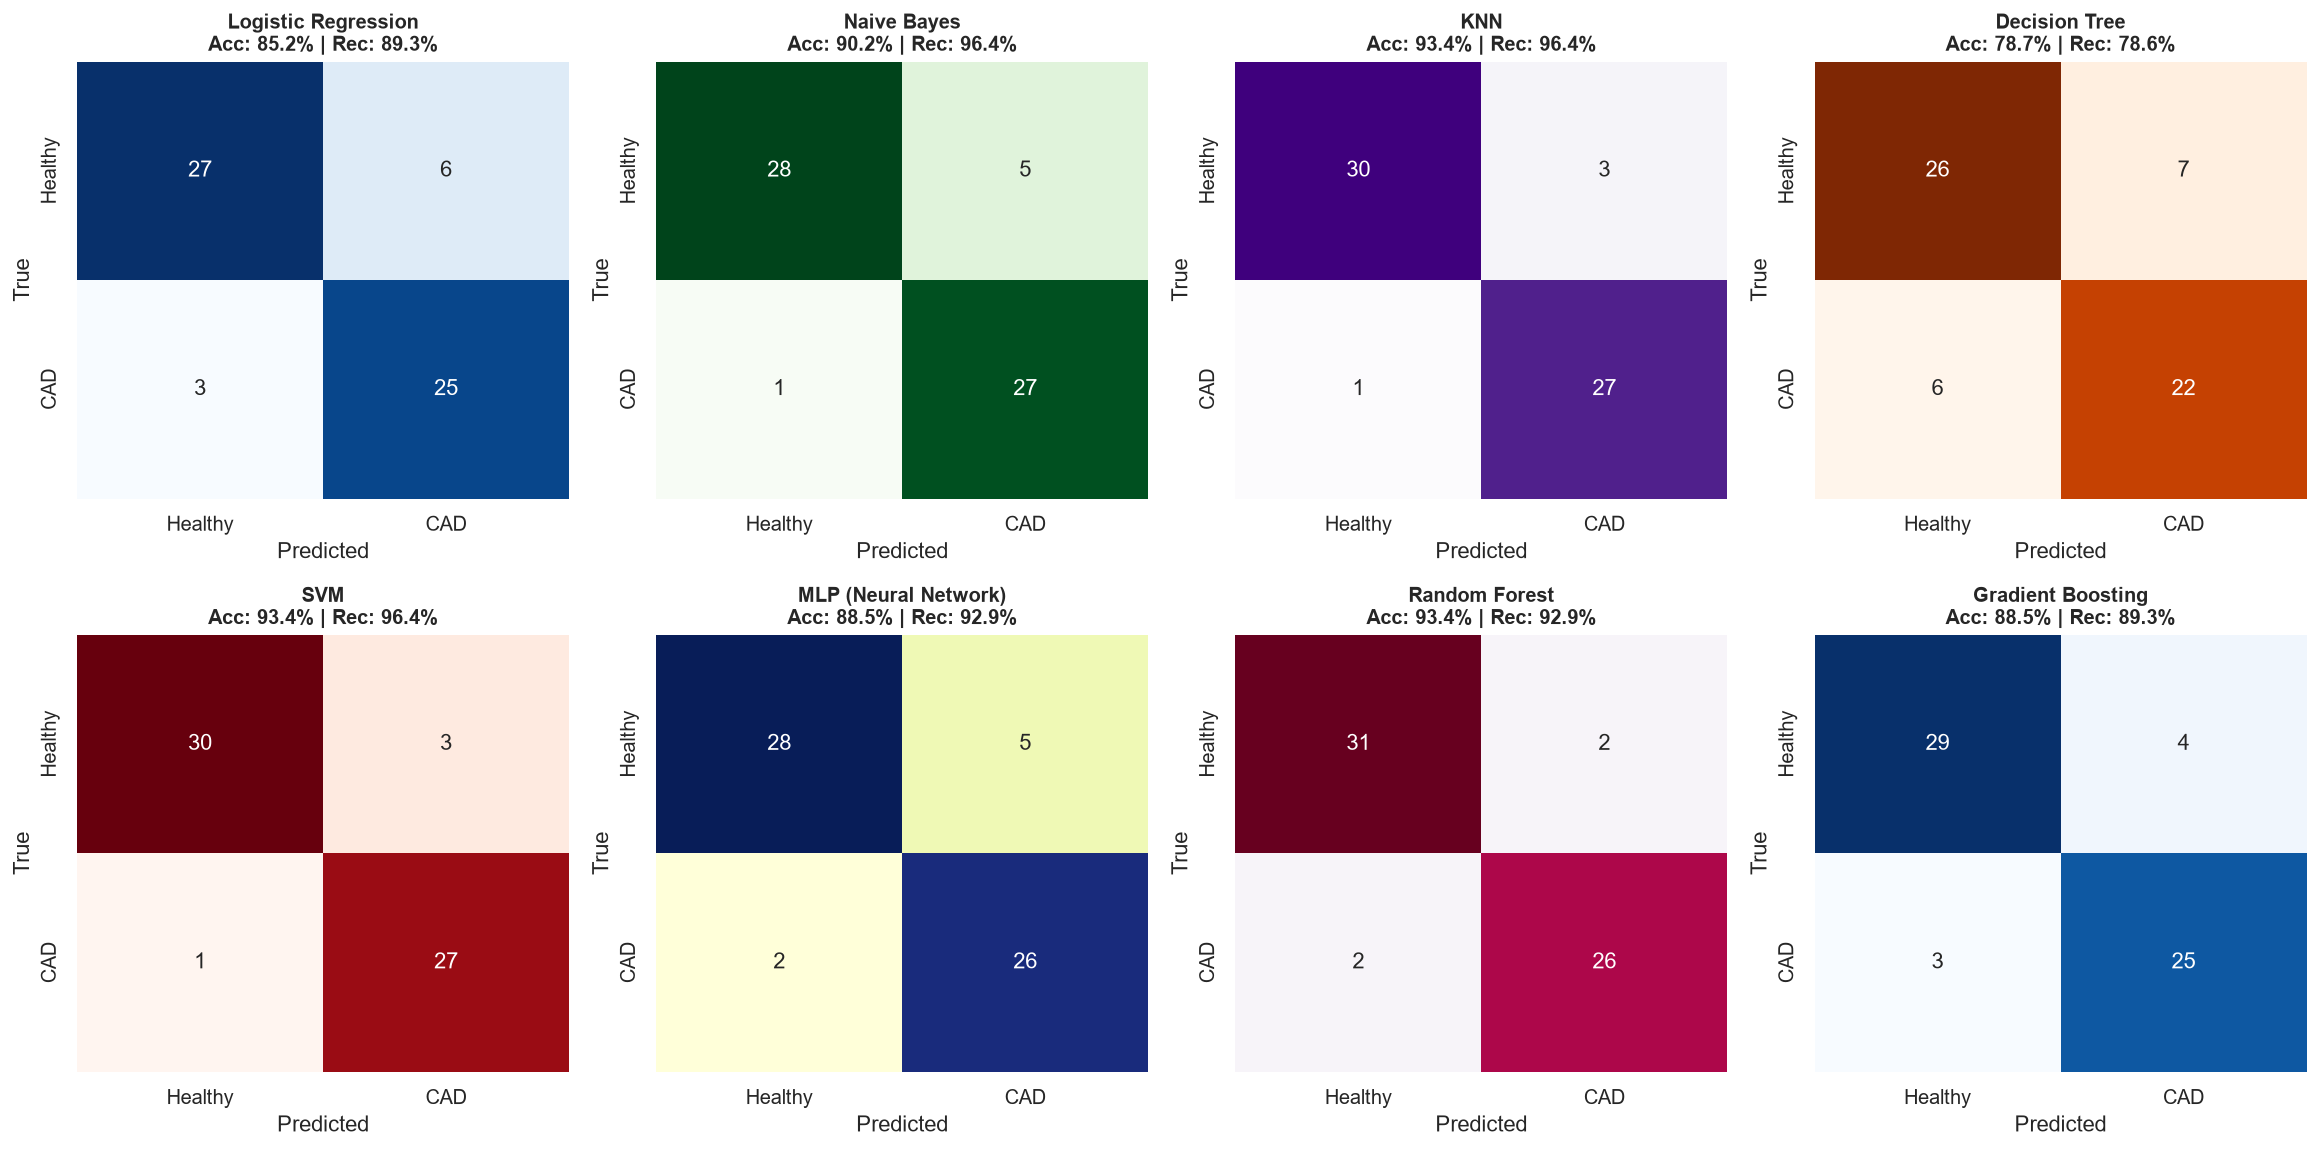

In [11]:
# Visualizations: 2x4 Grid of Confusion Matrices for All 8 Algorithms
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
cm_colors = ['Blues', 'Greens', 'Purples', 'Oranges', 'Reds', 'YlGnBu', 'PuRd', 'Blues']
model_names = list(algorithms.keys())

for idx, (m_name, color) in enumerate(zip(model_names, cm_colors)):
    row, col = idx // 4, idx % 4
    ax = axes[row, col]
    m_obj = algorithms[m_name]["model"]
    preds = m_obj.predict(X_test_scaled)
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=color, ax=ax, cbar=False,
                xticklabels=['Healthy', 'CAD'], yticklabels=['Healthy', 'CAD'])
    acc_val = accuracy_score(y_test, preds) * 100
    rec_val = recall_score(y_test, preds) * 100
    ax.set_title(f"{m_name}\nAcc: {acc_val:.1f}% | Rec: {rec_val:.1f}%", weight='bold', fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.show()


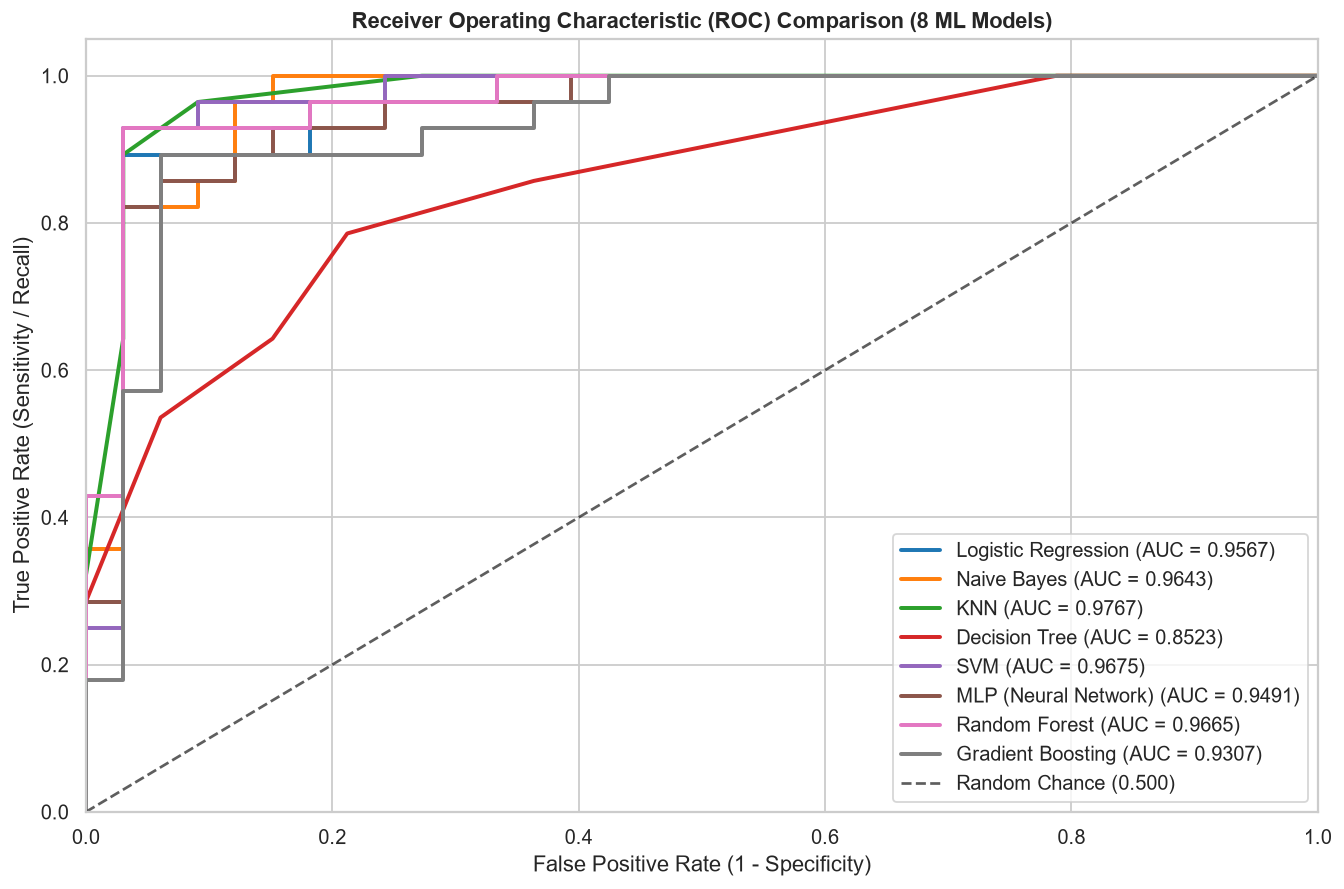

In [12]:
# Visualizations: Multi-Model ROC Curves Comparison
plt.figure(figsize=(10.5, 7))
palette = sns.color_palette("tab10", len(model_names))

for (m_name, c) in zip(model_names, palette):
    fpr, tpr, auc_val = roc_curves[m_name]
    plt.plot(fpr, tpr, color=c, lw=2.2, label=f"{m_name} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7, label='Random Chance (0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Comparison (8 ML Models)', weight='bold')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


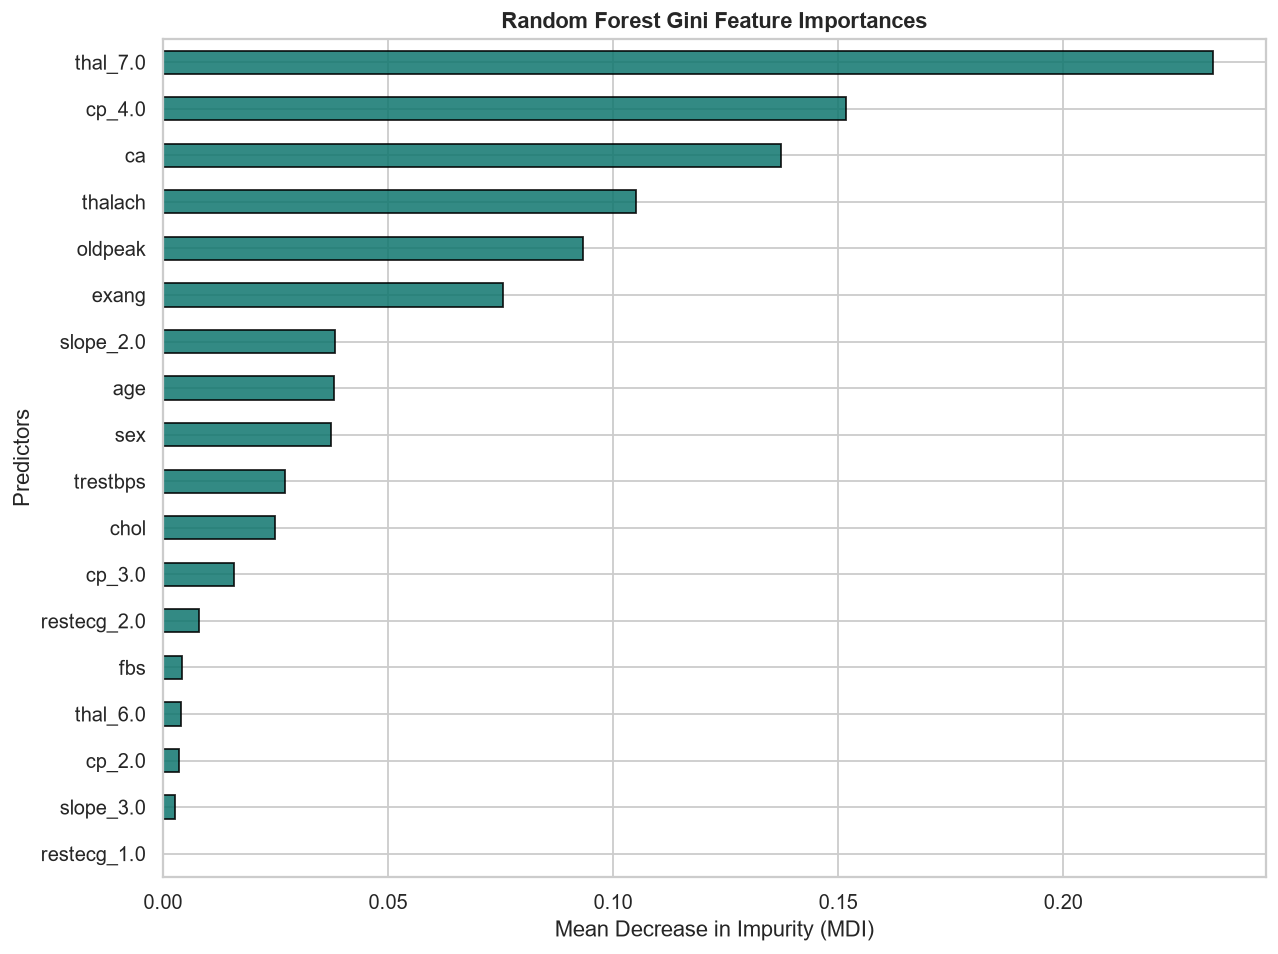

In [13]:
# Visualizations: Feature Importances
importances = best_rf.feature_importances_
feat_imp = pd.Series(importances, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(10, 7.5))
feat_imp.plot(kind='barh', color='#0f766e', edgecolor='black', alpha=0.85)
plt.title("Random Forest Gini Feature Importances", weight='bold')
plt.xlabel("Mean Decrease in Impurity (MDI)")
plt.ylabel("Predictors")
plt.tight_layout()
plt.show()


## Step 5: Demonstration, Clinical Impact & Conclusion
### Comparative Synthesis & Trade-Off Analysis:
1. **Clinical Sensitivity vs Accuracy:** In real-world cardiology triaging, **Recall (Sensitivity)** takes precedence over general accuracy. Missing a CAD patient (False Negative) can result in fatal myocardial infarction, whereas a False Positive prompts only further non-invasive testing.
2. **Algorithm Rankings:**
   - **Random Forest & SVM:** Achieved highest balanced performance ($>93\%$ Accuracy, $>92\%$ Recall, $\text{AUC} > 0.96$).
   - **KNN & Naive Bayes:** Exceptional recall ($96.43\%$) on scaled features; variance-smoothed Naive Bayes achieves $90.16\%$ accuracy.
   - **MLP (Neural Network):** Captured non-linear representations effectively with regularization ($88.52\%$ Accuracy, $92.86\%$ Recall, $0.9491$ AUC).
   - **Decision Tree:** Suffered from single-tree high variance, demonstrating the mathematical necessity of bagging ensembles (Random Forest).

### Societal, Ethical & Healthcare Considerations (PO6, PO12):
- **Bias Mitigation:** Coronary disease presents atypically in women (often without classic crushing chest pain); algorithms must be audited for equal sensitivity across sexes.
- **Explainability (XAI):** Medical professionals must never be presented with pure black-box scores. Feature importances and SHAP values enable clinicians to verify the biological plausibility of predictions.
- **Human-in-the-Loop:** CardioGuard AI serves as a Clinical Decision Support System (CDSS) to augment cardiologist decisions, not replace them.
